# 25. Optimizers with Core APIs

### Introduction

This notebook introduces the process of creating custom optimizers with the TensorFlow Core low-level APIs. Visit the Core APIs overview to learn more about TensorFlow Core and its intended use cases.

The Keras optimizers module is the recommended optimization toolkit for many general training purposes. It includes a variety of prebuilt optimizers as well as subclassing functionality for customization. The Keras optimizers are also compatible with custom layers, models, and training loops built with the Core APIs. These prebuilt and customizable optimizers are suitable for most cases, but the Core APIs allow for complete control over the optimization process. For example, techniques such as Sharpness-Aware Minimalization (SAM) require the model and optimizer to be coupled, which does not fit the traditional definition of ML optimizers. This guide walks through the process of building custom optimizers from scratch with the Core APIs, giving you the power to have full control over the structure, implementation, and behavior of your optimizers.

### Optimizers Overview

An optimizer is an algorithm used to minimize a loss function with respect to a model's trainable parameters. The most straightforward optimization technique is gradient descent, which iteratively updates a model's parameters by taking a step in the direction of its loss function's steepest descent. Its step size is directly proportional to the size of the gradient, which can be problematic when the gradient is either too large or too small. There are many other gradient-based optimizers such as Adam, Adagrad, and RMSprop that leverage various mathematical properties of gradients for memory efficiency and fast convergence.

### Setup

In [1]:
import matplotlib
from matplotlib import pyplot as plt
# Preset Matplotlib figure sizes.
matplotlib.rcParams['figure.figsize'] = [9, 6]

In [2]:
import tensorflow as tf
print(tf.__version__)
# Set random seed for reproducible results
tf.random.set_seed(22)

2.20.0


### Gradient descent

The basic optimizer class should have an initialization method and a function to update a list of variables given a list of gradients. Start by implementing the basic gradient descent optimizer which updates each variable by subtracting its gradient scaled by a learning rate.

In [3]:
class GradientDescent(tf.Module):
    def __init__(self, learning_rate=1e-3):
        # Initialize parameters
        self.learning_rate = learning_rate
        self.title = f"Gradient descent optimizer: learning rate={self.learning_rate}"

    def apply_gradients(self, grads, vars):
        # Update variables
        for grad, var in zip(grads, vars):
            var.assign_sub(self.learning_rate * grad)

To test this optimizer, create a sample loss function to minimize with respect to a single variable, x. Compute its gradient function and solve for its minimizing parameter value:

**L = 2x^4 + 3x^3 + 2**

**dl / dx = 8x^3 + 9x^2**

dl / dx is 0 at x = 0, which is a saddle point and at x = -9/8, which is the global minimum. Therefore, the loss function is optimized at x* = -9/8.

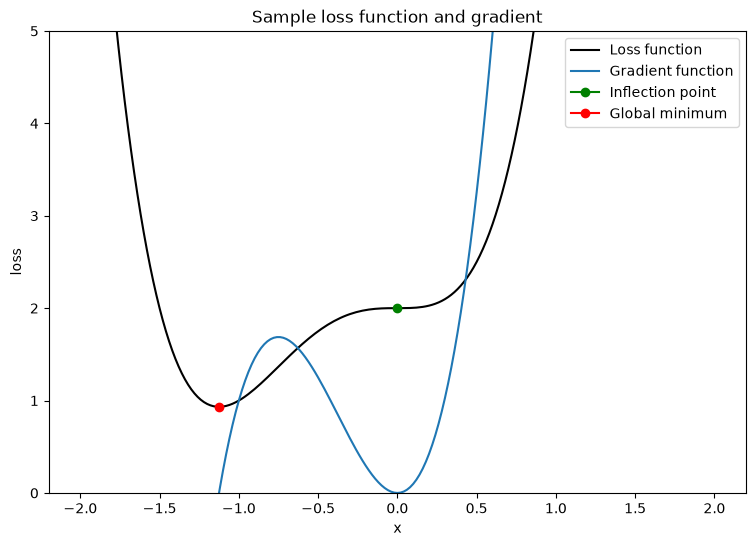

In [4]:
x_vals = tf.linspace(-2, 2, 201)
x_vals = tf.cast(x_vals, tf.float32)

def loss(x):
    return 2 * (x ** 4) + 3 * (x ** 3) + 2

def grad(f, x):
    with tf.GradientTape() as tape:
        tape.watch(x)
        result = f(x)
    return tape.gradient(result, x)

plt.plot(x_vals, loss(x_vals), c='k', label='Loss function')
plt.plot(x_vals, grad(loss, x_vals), c='tab:blue', label='Gradient function')
plt.plot(0, loss(0), marker='o', c='g', label='Inflection point')
plt.plot(-9/8, loss(-9/8), marker='o', c='r', label='Global minimum')
plt.legend()
plt.ylim(0,5)
plt.xlabel("x")
plt.ylabel("loss")
plt.title("Sample loss function and gradient");

Write a function to test the convergence of an optimizer with a single variable loss function. Assume that convergence has been achieved when the updated parameter's value at timestep t is the same as its value held at timestep t-1. Terminate the test after a set number of iterations and also keep track of any exploding gradients during the process. In order to truly challenge the optimization algorithm, initialize the parameter poorly. In the above example, x = 2 is a good choice since it involves an steep gradient and also leads into an inflection point.

In [5]:
def convergence_test(optimizer, loss_fn, grad_fn=grad, init_val=2., max_iters=2000):
    # Function for optimizer convergence test
    print(optimizer.title)
    print("--------------------------------")
    # Initializing variables and structures
    x_star = tf.Variable(init_val)
    param_path = []
    converged = False

    for iter in range(1, max_iters + 1):
        x_grad = grad_fn(loss_fn, x_star)

        # Case for exploding gradient
        if tf.math.is_nan(x_grad):
            print(f"Gradient exploded at iteration {iter}\n")
            return []

        # Updating the variable and storing its old-version
        x_old = x_star.numpy()
        optimizer.apply_gradients([x_grad,], [x_star])
        param_path.append(x_star.numpy())

        # Checking for convergence
        if x_star == x_old:
            print(f"Converged in {iter} iterations\n")
            converged = True
            break

    # Print early termination message
    if not converged:
        print(f"Exceeded maximum of {max_iters} iterations. Test terminated.\n")
    return param_path

Test the convergence of the gradient descent optimizer for the following learning rates: 1e-3, 1e-2, 1e-1

In [6]:
param_map_gd = {}
learning_rates = [1e-3, 1e-2, 1e-1]
for learning_rate in learning_rates:
    param_map_gd[learning_rate] = (convergence_test(GradientDescent(learning_rate=learning_rate), loss_fn=loss))

Gradient descent optimizer: learning rate=0.001
--------------------------------
Exceeded maximum of 2000 iterations. Test terminated.

Gradient descent optimizer: learning rate=0.01
--------------------------------
Exceeded maximum of 2000 iterations. Test terminated.

Gradient descent optimizer: learning rate=0.1
--------------------------------
Gradient exploded at iteration 6



Visualize the path of the parameters over a contour plot of the loss function.

In [7]:
def viz_paths(param_map, x_vals, loss_fn, title, max_iters=2000):
    # Creating a contour plot of the loss function
    t_vals = tf.range(1., max_iters + 100.)
    t_grid, x_grid = tf.meshgrid(t_vals, x_vals)
    loss_grid = tf.math.log(loss_fn(x_grid))
    plt.pcolormesh(t_vals, x_vals, loss_grid, vmin=0, shading='nearest')
    colors = ['r', 'w', 'c']
    # Plotting the parameter paths over the contour plot
    for i, learning_rate in enumerate(param_map):
        param_path = param_map[learning_rate]
        if len(param_path) > 0:
            x_star = param_path[-1]
            plt.plot(t_vals[:len(param_path)], param_path, c=colors[i])
            plt.plot(len(param_path), x_star, marker='o', c=colors[i], label=f"x*: learning rate={learning_rate}")
    plt.xlabel("Iterations")
    plt.ylabel("Parameter value")
    plt.legend()
    plt.title(f"{title} parameter paths")

C:\Users\yigit\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\events.py:100: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


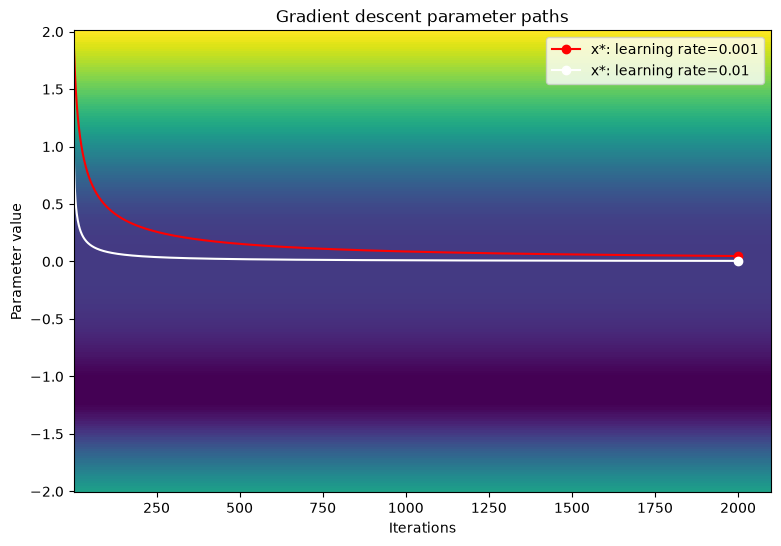

In [8]:
viz_paths(param_map_gd, x_vals, loss, "Gradient descent")

Gradient descent seems to get stuck at the inflection point when using smaller learning rates. Increasing the learning rate can encourage faster movement around the plateau region due to a large step size; however, this comes at the risk of having exploding gradients in early iterations when the loss function is extremely steep.

### Gradient descent with momentum

Gradient descent with momentum not only uses the gradient to update a variable but also involves the change in position of a variable based on its previous update. The momentum parameter determines the level of influence the update at timestep t-1 has on the update at timestep t. Accumulating momentum helps to move variables past plateau regions faster than basic gradient descent. The momentum update rule is as follows:

Δ_x^[t] = lr * L'(x^[t-1]) + p * Δ_x^[t-1]

x^[t] = x^[t-1] - Δ_x^[t]

where

* x : the variable being optimized

* Δ_x : change in x

* lr : learning rate

* L'(x) : gradient of the loss function with respect to x

* p : momentum parameter 

In [9]:
class Momentum(tf.Module):
    def __init__(self, learning_rate=1e-3, momentum=0.7):
        # Initialize parameters
        self.learning_rate = learning_rate
        self.momentum = momentum
        self.change = 0.
        self.title = f"Gradient descent optimizer: learning rate={self.learning_rate}"

    def apply_gradients(self, grads, vars):
        # Update variables
        for grad, var in zip(grads, vars):
            curr_change = self.learning_rate * grad + self.momentum * self.change
            var.assign_sub(curr_change)
            self.change = curr_change

Test the convergence of the momentum optimizer for the following learning rates: 1e-3, 1e-2, 1e-1

In [10]:
param_map_mtm = {}
learning_rates = [1e-3, 1e-2, 1e-1]
for learning_rate in learning_rates:
    param_map_mtm[learning_rate] = (convergence_test(Momentum(learning_rate=learning_rate), loss_fn=loss, grad_fn=grad))

Gradient descent optimizer: learning rate=0.001
--------------------------------
Exceeded maximum of 2000 iterations. Test terminated.

Gradient descent optimizer: learning rate=0.01
--------------------------------
Converged in 80 iterations

Gradient descent optimizer: learning rate=0.1
--------------------------------
Gradient exploded at iteration 6



Visualize the path of the parameters over a contour plot of the loss function.

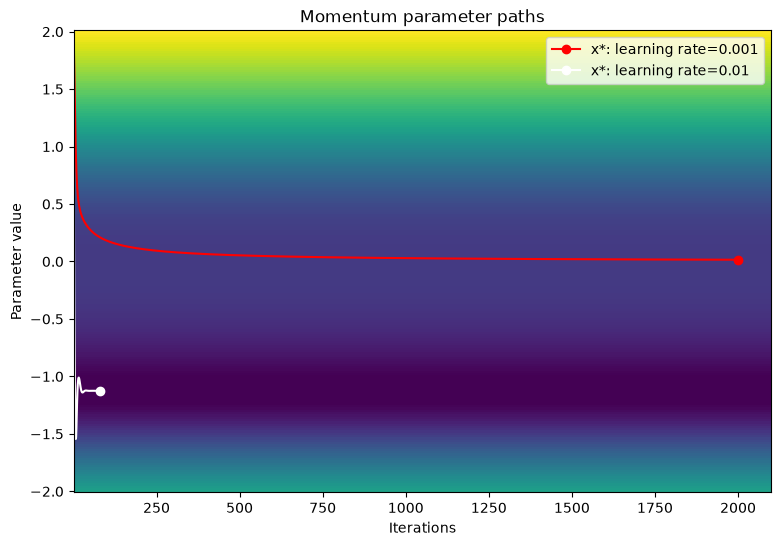

In [11]:
viz_paths(param_map_mtm, x_vals, loss, "Momentum")

### Adaptive moment estimation (Adam)

The Adaptive Moment Estimation (Adam) algorithm is an efficient and highly generalizable optimization technique that leverages two key gradient descent methodologies: momentum, and root mean square propagation (RMSP). Momentum helps accelerate gradient descent by using the first moment (sum of gradients) along with a decay parameter. RMSP is similar; however, it leverages the second moment (sum of gradients squared).

The Adam algorithm combines both the first and second moment to provide a more generalizable update rule. The sign of a variable, x, can be determined by computing x / sqrt(x^2). The Adam optimizer uses this fact to calculate an update step which is effectively a smoothed sign. Instead of calculating x / sqrt(x^2), the optimizer calculates a smoothed version of x (first moment) and x^2 (secomd moment) for each variable update.

**Adam algorithm**

β_1 <-- 0.9 : literature value

β_2 <-- 0.999 : literature value

lr <-- 1e-3 : configurable learning rate

ε <-- 1e-7 : prevents divide by 0 error

V_dv <-- 0-> n x 1 : stores momentum updates for each variable

S_dv <-- 0-> n x 1 : stores RMSP updates for each variable

t <-- 1

On iteration t:

For (dL/dv, v) in gradient variable pairs:

V_dv_i = β_1 * V_dv_i + (1 - β_1) dL/dv : momentum update

S_dv_i = β_2 * V_dv_i + (1 - β_2)(dL/dv)^2 : RMSP update

v_dv^bc = V_dv_i / (1 - β_1)^t : momentum bias correction

s_dv^bc = S_dv_i / (1 - β_2)^t : RMSP bias correction

v = v - lr * (v_dv_bc) / (sqrt(s_dv^bc) + ε) : parameter update

t = t + 1

**End of algorithm**

Given that V_dv and S_dv are initialized to 0 and that β_1 and β_2 are close to 1, the moemntum and RMSP updates are naturally biased towards 0; therefore, the variables can benefit from bias correction. Bias correction also helps to control the osccilation of weights as they approach the global minimum.

In [12]:
class Adam(tf.Module):
    def __init__(self, learning_rate=1e-3, beta_1=0.9, beta_2=0.999, ep=1e-7):
        # Initializer the Adam parameters
        self.beta_1 = beta_1
        self.beta_2 = beta_2
        self.learning_rate = learning_rate
        self.ep = ep
        self.t = 1.
        self.v_dvar, self.s_dvar = [], []
        self.title = f"Adam: learning rate={self.learning_rate}"
        self.built = False

    def apply_gradients(self, grads, vars):
        # Set up moment and RMSprop slots for each variable on the first call
        if not self.built:
            for var in vars:
                v = tf.Variable(tf.zeros(shape=var.shape))
                s = tf.Variable(tf.zeros(shape=var.shape))
                self.v_dvar.append(v)
                self.s_dvar.append(s)
            self.built = True
        # Perform Adam updates
        for i, (d_var, var) in enumerate(zip(grads, vars)):
            # Moment calculation
            self.v_dvar[i] = self.beta_1 * self.v_dvar[i] + (1-self.beta_1) * d_var
            # RMSprop calculation
            self.s_dvar[i] = self.beta_2 * self.s_dvar[i] + (1-self.beta_2) * tf.square(d_var)
            # Bias correction
            v_dvar_bc = self.v_dvar[i] / (1-(self.beta_1 ** self.t))
            s_dvar_bc = self.s_dvar[i] / (1-(self.beta_2 ** self.t))
            # Update model variables
            var.assign_sub(self.learning_rate * (v_dvar_bc / (tf.sqrt(s_dvar_bc) + self.ep)))
        # Increment the iteration counter
        self.t += 1.

Test the performance of the Adam optimizer with the same learning rates used with the gradient descent examples.

In [13]:
param_map_adam = {}
learning_rates = [1e-3, 1e-2, 1e-1]
for learning_rate in learning_rates:
    param_map_adam[learning_rate] = (convergence_test(Adam(learning_rate=learning_rate), loss_fn=loss))

Adam: learning rate=0.001
--------------------------------
Exceeded maximum of 2000 iterations. Test terminated.

Adam: learning rate=0.01
--------------------------------
Exceeded maximum of 2000 iterations. Test terminated.

Adam: learning rate=0.1
--------------------------------
Converged in 1156 iterations



Visualize the path of the parameters over a contour plot of the loss function.

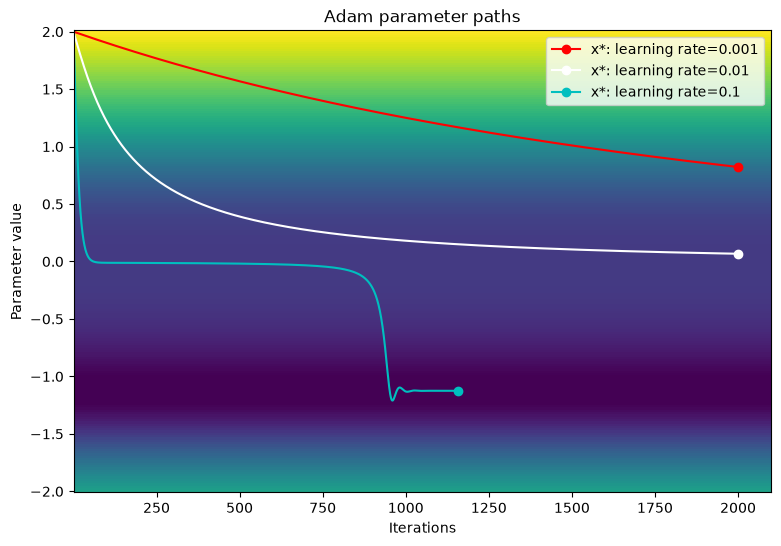

In [14]:
viz_paths(param_map_adam, x_vals, loss, "Adam")

In this particular example, the Adam optimizer has slower convergence compared to traditional gradient descent when using small learning rates. However, the algorithm successfully moves past the plateau region and converges to the global minimum when a large learning rate. Exploding gradients are no longer an issue due to Adam's dynamic scaling of learning rates when encountering large gradients.

### Conclusion

This notebook introducted the basics of writing and comparing optimizers with the TensorFlow Core APIs. Although prebuilt optimizers like Adam are generalizable, they may not always be the best choice for every model or dataset. Having fine-grained control over the optimization process can help streamline ML training workflows and improve overall performance. Refer to the following documentation for more examples of custom optimizers:

* This Adam optimizer is used in the Multilayer perceptrons tutorial and the Distributed training.
* Model Garden has a variety of custom optimizers written with the Core APIs.